In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("adult.data", sep=",")

In [3]:
df.sample(10)

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
25427,22,Private,34443,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,25,United-States,<=50K
13728,39,Private,181553,Bachelors,13,Divorced,Exec-managerial,Not-in-family,White,Male,0,0,55,United-States,<=50K
2294,21,Private,212619,Assoc-voc,11,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States,<=50K
32035,18,Private,36162,11th,7,Never-married,Craft-repair,Own-child,White,Male,0,0,5,United-States,<=50K
16338,34,State-gov,171216,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Male,0,0,50,United-States,<=50K
23166,40,Self-emp-inc,225165,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,<=50K
9652,25,Private,134113,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,0,0,30,United-States,<=50K
20925,22,Private,142566,HS-grad,9,Never-married,Sales,Not-in-family,White,Male,0,0,40,United-States,<=50K
25266,26,Private,287797,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,45,United-States,<=50K
22665,21,Private,241367,Some-college,10,Never-married,Adm-clerical,Own-child,White,Male,0,0,10,United-States,<=50K


In [4]:
columns=["age","workclass","fnlwgt","education","education-num","marital-status","occupation","relationship","race","sex","capital-gain","capital-loss","hours-per-week","native-country","class"]

In [5]:
l=list(df.columns)
df.columns=columns
df.loc[len(df)]=l

In [6]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
class             0
dtype: int64

In [7]:
df.dtypes

age               object
workclass            str
fnlwgt            object
education            str
education-num     object
marital-status       str
occupation           str
relationship         str
race                 str
sex                  str
capital-gain      object
capital-loss      object
hours-per-week    object
native-country       str
class                str
dtype: object

In [8]:
df.shape

(32561, 15)

In [9]:
columns=df.columns
for i in columns:
    print(i,":",df[i].unique())

age : [50 38 53 28 37 49 52 31 42 30 23 32 40 34 25 43 54 35 59 56 19 39 20 45
 22 48 21 24 57 44 41 29 18 47 46 36 79 27 67 33 76 17 55 61 70 64 71 68
 66 51 58 26 60 90 75 65 77 62 63 80 72 74 69 73 81 78 88 82 83 84 85 86
 87 '39']
workclass : <StringArray>
[' Self-emp-not-inc',          ' Private',        ' State-gov',
      ' Federal-gov',        ' Local-gov',                ' ?',
     ' Self-emp-inc',      ' Without-pay',     ' Never-worked']
Length: 9, dtype: str
fnlwgt : [83311 215646 234721 ... 84661 257302 ' 77516']
education : <StringArray>
[   ' Bachelors',      ' HS-grad',         ' 11th',      ' Masters',
          ' 9th', ' Some-college',   ' Assoc-acdm',    ' Assoc-voc',
      ' 7th-8th',    ' Doctorate',  ' Prof-school',      ' 5th-6th',
         ' 10th',      ' 1st-4th',    ' Preschool',         ' 12th']
Length: 16, dtype: str
education-num : [13 9 7 14 5 10 12 11 4 16 15 3 6 2 1 8 ' 13']
marital-status : <StringArray>
[   ' Married-civ-spouse',              ' Divorce

In [10]:
df["married"]=0

In [11]:
l=[' Married-civ-spouse',' Married-AF-spouse',]
df["married"]=df["marital-status"].apply(lambda x: 1 if x in l else 0)
df.drop(["marital-status"],axis=1,inplace=True)

In [12]:
df.sample(10)

,age,workclass,fnlwgt,education,education-num,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class,married
9666,23,Private,143032,Masters,14,Prof-specialty,Own-child,White,Female,0,0,36,United-States,<=50K,0
2751,53,Self-emp-not-inc,174102,7th-8th,4,Exec-managerial,Husband,White,Male,4386,0,50,Greece,>50K,1
19573,55,Local-gov,107308,Masters,14,Prof-specialty,Husband,White,Male,0,0,40,United-States,>50K,1
29817,24,Private,196742,HS-grad,9,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K,0
15637,39,Private,218916,Prof-school,15,Exec-managerial,Not-in-family,White,Male,0,0,50,United-States,<=50K,0
26842,47,Private,239865,HS-grad,9,Craft-repair,Husband,White,Male,0,1977,45,United-States,>50K,1
30843,36,Private,134367,HS-grad,9,Other-service,Own-child,White,Female,0,0,30,United-States,<=50K,0
30760,62,Private,81116,Some-college,10,Adm-clerical,Not-in-family,White,Male,0,1974,40,United-States,<=50K,0
5322,31,Private,49923,HS-grad,9,Transport-moving,Husband,White,Male,0,0,40,United-States,<=50K,1
6073,55,Private,169611,11th,7,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K,0


In [13]:
columns=df.columns
for i in columns:
    print(i,":",df[i].unique())

age : [50 38 53 28 37 49 52 31 42 30 23 32 40 34 25 43 54 35 59 56 19 39 20 45
 22 48 21 24 57 44 41 29 18 47 46 36 79 27 67 33 76 17 55 61 70 64 71 68
 66 51 58 26 60 90 75 65 77 62 63 80 72 74 69 73 81 78 88 82 83 84 85 86
 87 '39']
workclass : <StringArray>
[' Self-emp-not-inc',          ' Private',        ' State-gov',
      ' Federal-gov',        ' Local-gov',                ' ?',
     ' Self-emp-inc',      ' Without-pay',     ' Never-worked']
Length: 9, dtype: str
fnlwgt : [83311 215646 234721 ... 84661 257302 ' 77516']
education : <StringArray>
[   ' Bachelors',      ' HS-grad',         ' 11th',      ' Masters',
          ' 9th', ' Some-college',   ' Assoc-acdm',    ' Assoc-voc',
      ' 7th-8th',    ' Doctorate',  ' Prof-school',      ' 5th-6th',
         ' 10th',      ' 1st-4th',    ' Preschool',         ' 12th']
Length: 16, dtype: str
education-num : [13 9 7 14 5 10 12 11 4 16 15 3 6 2 1 8 ' 13']
occupation : <StringArray>
[  ' Exec-managerial', ' Handlers-cleaners',    ' Pro

In [14]:
df["occupation"].value_counts()

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
?                    1843
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64

In [15]:
df["workclass"] = df["workclass"].str.strip().replace("?",np.nan)

In [16]:
df["occupation"] = df["occupation"].str.strip().replace("?",np.nan)

In [17]:
df["class"]=df["class"].str.strip().replace("<=50K", 0).replace(">50K", 1)

In [18]:
df["sex"]=df["sex"].str.strip().replace("Male", 0).replace("Female", 1)

In [19]:
df["married"]=df["married"].astype("Int16")

In [20]:
df.drop([32560], inplace=True)

In [21]:
df["age"]=df["age"].astype("Int16")

In [22]:
df.sample(5)

,age,workclass,fnlwgt,education,education-num,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class,married
27904,36,Private,179488,Some-college,10,Adm-clerical,Unmarried,White,0,0,0,40,Canada,0,0
2596,37,Private,269329,Assoc-voc,11,Prof-specialty,Not-in-family,White,1,8614,0,45,United-States,1,0
17659,26,Private,196805,Some-college,10,Transport-moving,Husband,Black,0,0,0,65,United-States,0,1
6977,24,Self-emp-not-inc,191954,7th-8th,4,Farming-fishing,Own-child,White,0,0,0,50,United-States,0,0
163,45,Self-emp-not-inc,201080,Masters,14,Sales,Husband,White,0,0,0,40,United-States,1,1


In [23]:
df.drop(['education'],axis=1,inplace=True)

In [24]:
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education-num        0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country       0
class                0
married              0
dtype: int64

In [25]:
df.dtypes

age                Int16
workclass            str
fnlwgt            object
education-num     object
occupation           str
relationship         str
race                 str
sex               object
capital-gain      object
capital-loss      object
hours-per-week    object
native-country       str
class             object
married            Int16
dtype: object

In [26]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
categorical_features = [
    'workclass', 
    'occupation', 
    'relationship', 
    'race', 
    'native-country'
]
for col in categorical_features:
    df[col] = encoder.fit_transform(df[col])

In [27]:
df.sample(5)

,age,workclass,fnlwgt,education-num,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class,married
10512,21,3,148294,9,4,3,4,0,0,0,20,39,0,0
31288,33,1,251521,13,3,1,4,1,0,0,50,39,0,0
2211,42,3,70055,9,5,0,4,0,0,0,40,39,0,1
31944,32,3,124187,5,4,0,2,0,0,0,40,39,0,1
21175,64,8,104756,10,14,4,4,1,0,0,8,39,0,0


In [36]:
for col in ["capital-gain", "capital-loss"]:
    values = pd.to_numeric(df[col], errors="coerce")
    df[f"{col}-log"] = np.log1p(values)

df.drop(["capital-gain", "capital-loss"], axis=1, inplace=True)

In [37]:
df.to_csv("adult_cleaned.csv",index=False)

THE DATA IS CLEANED NOW EDA STARTS.

In [30]:
df1=df[["age","fnlwgt","education-num","capital-gain","capital-loss","hours-per-week","married","class"]]

<Axes: >

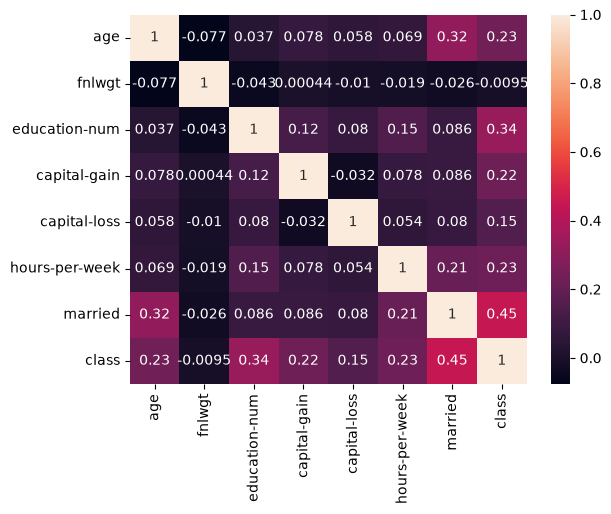

In [31]:
sns.heatmap(df1.corr(),annot=True)

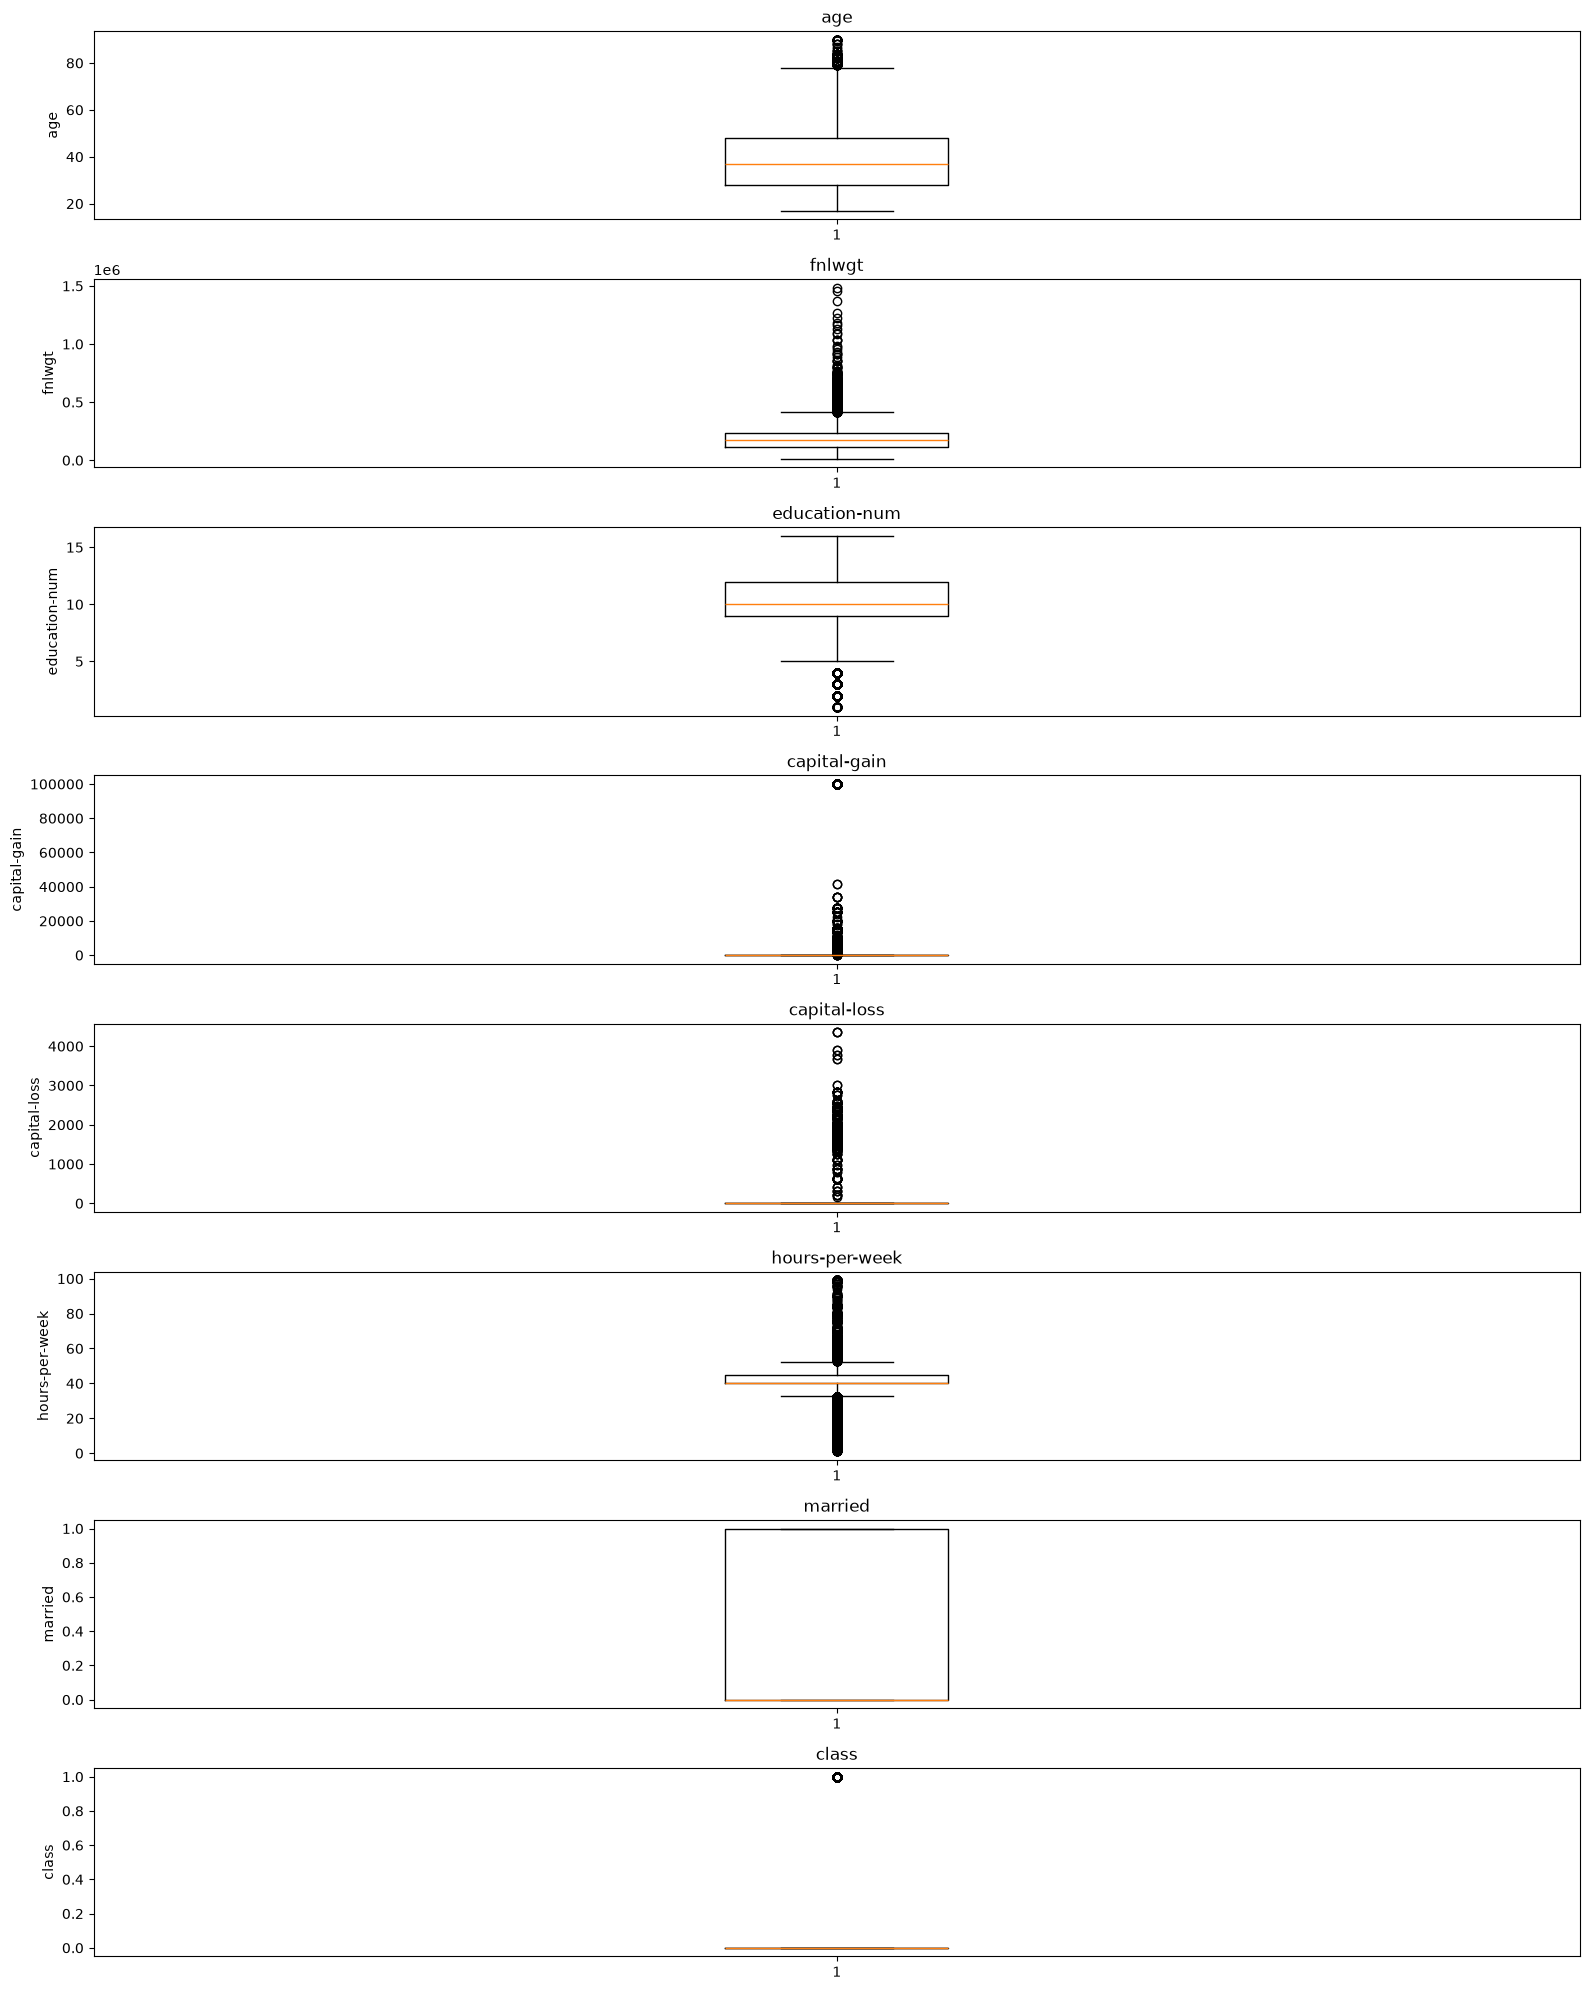

In [32]:
numeric_df1 = df1.apply(pd.to_numeric, errors="coerce")

fig, axes = plt.subplots(nrows=len(numeric_df1.columns), ncols=1, figsize=(16, 20))

for ax, column in zip(axes, numeric_df1.columns):
    values = numeric_df1[column].dropna().to_numpy()
    ax.boxplot(values)
    ax.set_title(column)
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

<Axes: xlabel='capital-gain', ylabel='Density'>

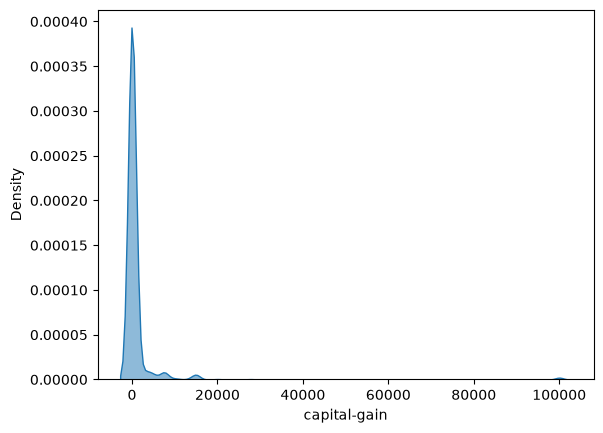

In [35]:
sns.kdeplot(data=df1, x="capital-gain", fill=True, common_norm=False, alpha=0.5)

<Axes: xlabel='capital-loss', ylabel='Density'>

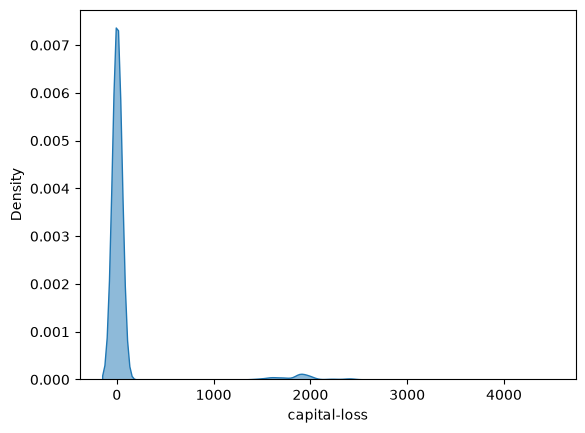

In [36]:
sns.kdeplot(data=df1, x="capital-loss", fill=True, common_norm=False, alpha=0.5)

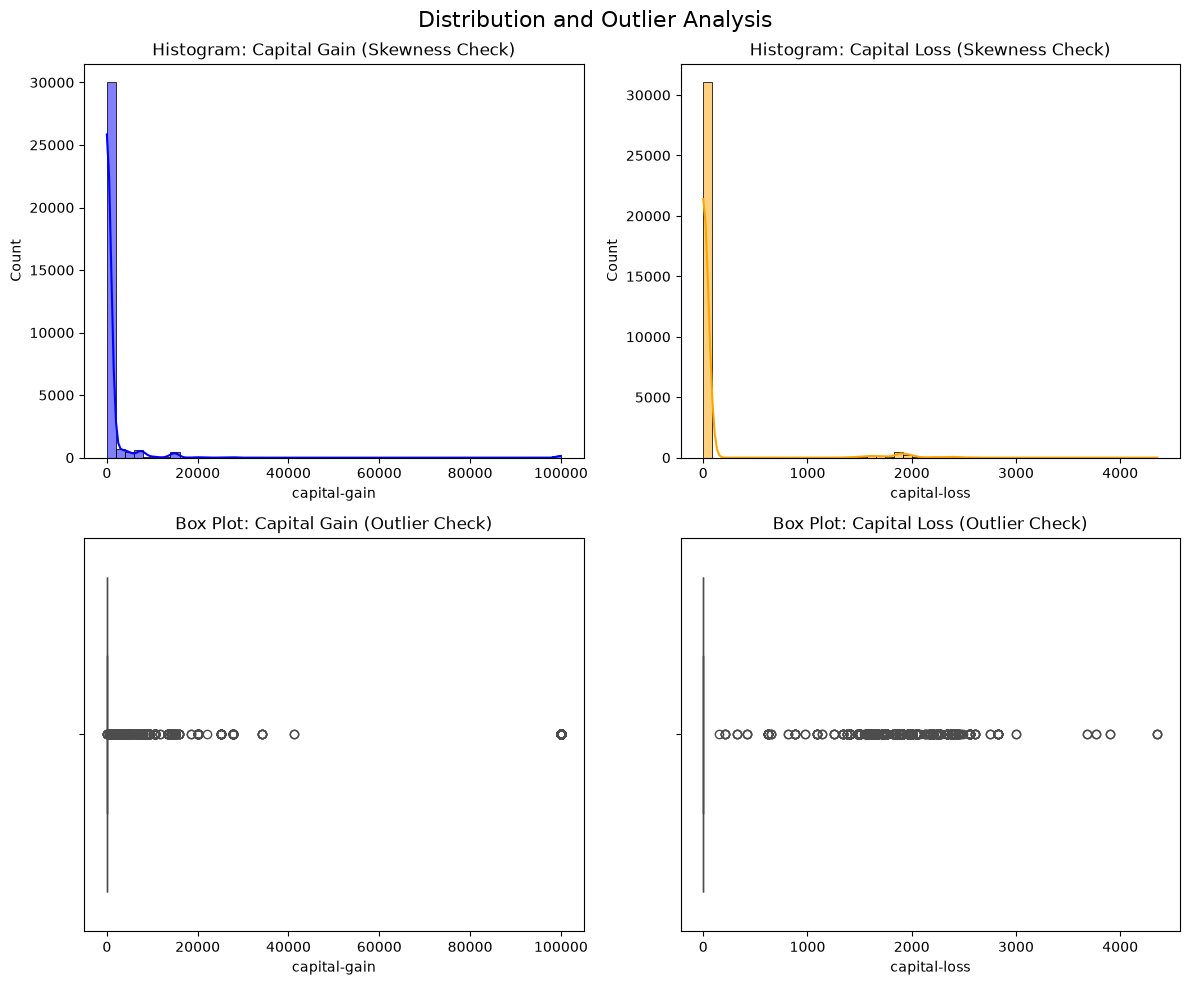

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Distribution and Outlier Analysis', fontsize=16)
sns.histplot(df['capital-gain'], bins=50, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Histogram: Capital Gain (Skewness Check)')

sns.histplot(df['capital-loss'], bins=50, kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Histogram: Capital Loss (Skewness Check)')
sns.boxplot(x=df['capital-gain'], ax=axes[1, 0], color='blue')
axes[1, 0].set_title('Box Plot: Capital Gain (Outlier Check)')

sns.boxplot(x=df['capital-loss'], ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Box Plot: Capital Loss (Outlier Check)')

plt.tight_layout()
plt.show()